# Лабораторна робота 1. Policy Iteration і Value Iteration для MountainCar-v0

Стан `MountainCar-v0` - пара (x, v): положення x ∈ [-1.2, 0.6] і швидкість v ∈ [-0.07, 0.07]. Дії: 0 - ліворуч, 1 - нічого, 2 - праворуч. Винагорода -1 за крок, епізод закінчується при x ≥ 0.5 або після 200 кроків.

Policy Iteration і Value Iteration працюють зі скінченною MDP, тому прямокутник станів ділимо на сітку комірок, а ймовірності переходу P(s'|s,a) оцінюємо з рівнянь руху середовища.

In [37]:
try:
    import gymnasium as gym
except ImportError:
    %pip install -q "gymnasium[classic-control]" matplotlib
    import gymnasium as gym
import time
import matplotlib.pyplot as plt
import numpy as np

N_X, N_V = 41, 41     # комірок за x і за v (непарне N_V: v = 0 у центрі комірки)
K = 4                 # точок на комірку по кожній осі, разом K*K
GAMMA, THETA = 0.99, 1e-6
EPISODES = 1000

env = gym.make("MountainCar-v0")
car = env.unwrapped
x_edges = np.linspace(car.min_position, car.max_position, N_X + 1)
v_edges = np.linspace(-car.max_speed, car.max_speed, N_V + 1)
N_S, N_A = N_X * N_V, env.action_space.n


def to_state(x, v):
    return np.digitize(x, x_edges[1:-1]) * N_V + np.digitize(v, v_edges[1:-1])

## Модель переходів

`step` повторює `MountainCarEnv.step` над масивами. У кожній комірці беремо K×K точок рівномірною сіткою, робимо з кожної один крок і запам’ятовуємо комірку-наступника або факт досягнення цілі. P(s'|s,a) - частка точок, що потрапили в s'. Одна точка в центрі комірки не підходить: за малої швидкості вона повертається в ту саму комірку, і модель отримує петлі, з яких немає виходу.

In [45]:
def step(x, v, a):
    v = np.clip(v + (a - 1) * car.force - np.cos(3 * x) * car.gravity, -car.max_speed, car.max_speed)
    x = np.clip(x + v, car.min_position, car.max_position)
    v = np.where((x == car.min_position) & (v < 0), 0.0, v)
    return x, v, (x >= car.goal_position) & (v >= car.goal_velocity)


off = (np.arange(K) + 0.5) / K
xs = (x_edges[:-1, None] + np.diff(x_edges)[:, None] * off)           # (N_X, K)
vs = (v_edges[:-1, None] + np.diff(v_edges)[:, None] * off)           # (N_V, K)
X = np.broadcast_to(xs[:, None, :, None], (N_X, N_V, K, K)).reshape(N_S, K * K)
V = np.broadcast_to(vs[None, :, None, :], (N_X, N_V, K, K)).reshape(N_S, K * K)

# print(X)
# print("---")
# print(V)

NEXT = np.empty((N_S, N_A, K * K), dtype=int)   # комірка-наступник кожної точки

DONE = np.empty((N_S, N_A, K * K), dtype=bool)  # точка досягла цілі

for a in range(N_A):
    x2, v2, d = step(X, V, a)
    NEXT[:, a], DONE[:, a] = to_state(x2, v2), d

# print("NEXT")
# print(NEXT)
# print("DONE")
# print(DONE)

def q_values(V):
    """Q(s,a) = -1 + γ·Σ P(s'|s,a)·V(s'); у термінальному стані V = 0."""
    return -1 + GAMMA * np.where(DONE, 0.0, V[NEXT]).mean(axis=2)

## Policy Iteration

Оцінювання: V(s) ← -1 + γ·Σ P(s'|s,π(s))·V(s') до max|ΔV| < θ. Покращення: π(s) ← argmax_a Q(s,a). Зупиняємося, коли політика не змінилася. Початкова політика - штовхати в напрямку швидкості.

In [ ]:
def policy_iteration():
    pi = np.where(np.tile(v_edges[:-1] + v_edges[1:], N_X) >= 0, 2, 0)
    V = np.zeros(N_S)
    rows, sweeps = np.arange(N_S), []          # проходів оцінювання на кожній ітерації
    while True:
        sweeps.append(0)
        while True:
            V_new = q_values(V)[rows, pi] # JUST DP !
            sweeps[-1] += 1
            delta, V = np.abs(V_new - V).max(), V_new
            if delta < THETA:
                break
        Q = q_values(V)
        best = Q.argmax(axis=1)
        keep = Q[rows, pi] >= Q[rows, best] - 1e-9          # нічия: залишаємо стару дію
        new_pi = np.where(keep, pi, best)
        if (new_pi == pi).all():
            return V, pi, sweeps
        pi = new_pi


t0 = time.perf_counter()
V_pi, pi_pi, pi_hist = policy_iteration()
pi_time = time.perf_counter() - t0
pi_iters, pi_sweeps = len(pi_hist), sum(pi_hist)
print(f"PI: {pi_iters} ітерацій, {pi_sweeps} проходів оцінювання ({pi_hist}), {pi_time:.2f} с")

PI: 9 ітерацій, 2027 проходів оцінювання ([1376, 228, 137, 100, 72, 58, 35, 12, 9]), 0.56 с


## Value Iteration

V(s) ← max_a [-1 + γ·Σ P(s'|s,a)·V(s')] до max|ΔV| < θ, потім π(s) = argmax_a Q(s,a).

In [40]:
def value_iteration():
    V, sweeps = np.zeros(N_S), 0
    while True:
        V_new = q_values(V).max(axis=1)
        sweeps += 1
        delta, V = np.abs(V_new - V).max(), V_new
        if delta < THETA:
            return V, q_values(V).argmax(axis=1), sweeps


t0 = time.perf_counter()
V_vi, pi_vi, vi_sweeps = value_iteration()
vi_time = time.perf_counter() - t0
print(f"VI: {vi_sweeps} проходів, {vi_time:.2f} с")

VI: 287 проходів, 0.09 с


## Порівняння

Кожну політику запускаємо в справжньому середовищі `EPISODES` разів з однаковими сідами і рахуємо успіхи та кроки до цілі.

                              PI        VI
ітерацій / проходів     9 / 2027       287
час, с                      0.56      0.09
успіхів                     1000      1000
середньо кроків            104.7     104.7

max|V_PI - V_VI| = 1.5e-05
політики збігаються в 94.2% комірок; розбіжностей поза нічиїми: 0


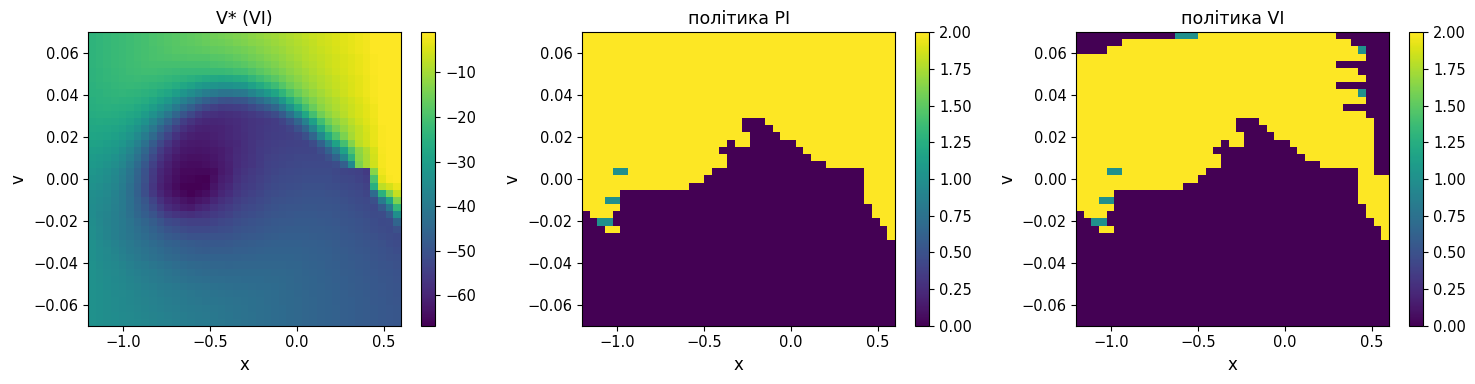

In [41]:
def run(policy, seed):
    (x, v), _ = env.reset(seed=seed)
    for t in range(1, 201):
        (x, v), _, term, trunc, _ = env.step(int(policy[to_state(x, v)]))
        if term or trunc:
            return term, t


res = {name: np.array([run(p, s) for s in range(EPISODES)]) for name, p in [("PI", pi_pi), ("VI", pi_vi)]}
Q = q_values(V_vi)
ties = np.sort(Q, axis=1)[:, -1] - np.sort(Q, axis=1)[:, -2] < 1e-9
same = pi_pi == pi_vi

print(f"{'':22}{'PI':>10}{'VI':>10}")
print(f"{'ітерацій / проходів':22}{f'{pi_iters} / {pi_sweeps}':>10}{vi_sweeps:>10}")
print(f"{'час, с':22}{pi_time:>10.2f}{vi_time:>10.2f}")
print(f"{'успіхів':22}{res['PI'][:, 0].sum():>10}{res['VI'][:, 0].sum():>10}")
print(f"{'середньо кроків':22}{res['PI'][:, 1].mean():>10.1f}{res['VI'][:, 1].mean():>10.1f}")
print(f"\nmax|V_PI - V_VI| = {np.abs(V_pi - V_vi).max():.1e}")
print(f"політики збігаються в {same.mean():.1%} комірок; розбіжностей поза нічиїми: {(~same & ~ties).sum()}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ext = [car.min_position, car.max_position, -car.max_speed, car.max_speed]
for a_, data, title in [(ax[0], V_vi, "V* (VI)"), (ax[1], pi_pi, "політика PI"), (ax[2], pi_vi, "політика VI")]:
    im = a_.imshow(data.reshape(N_X, N_V).T, origin="lower", aspect="auto", extent=ext)
    a_.set(title=title, xlabel="x", ylabel="v")
    fig.colorbar(im, ax=a_)
plt.tight_layout()
plt.show()

## Збереження

`results/lab1/dp_results.npz` - політики і цінності PI та VI на сітці, з ними порівнює ЛР2. `results/lab1/summary.json` - підсумкові числа.

In [42]:
import json
from pathlib import Path

OUT = Path("results") / "lab1"
OUT.mkdir(parents=True, exist_ok=True)
np.savez(OUT / "dp_results.npz", pi_pi=pi_pi, pi_vi=pi_vi, V_pi=V_pi, V_vi=V_vi, n_x=N_X, n_v=N_V, gamma=GAMMA)
summary = {
    "config": {"n_x": N_X, "n_v": N_V, "samples_per_cell": K * K, "gamma": GAMMA, "theta": THETA, "episodes": EPISODES},
    "pi": {"iterations": pi_iters, "eval_sweeps": pi_sweeps, "sweeps_per_iteration": pi_hist, "time_s": pi_time,
           "v_min": float(V_pi.min())},
    "vi": {"sweeps": vi_sweeps, "time_s": vi_time, "v_min": float(V_vi.min()), "error_bound": GAMMA * THETA / (1 - GAMMA)},
    "comparison": {"max_abs_v_diff": float(np.abs(V_pi - V_vi).max()), "agreement_pct": float(same.mean() * 100),
                   "disagreeing_cells": int((~same).sum()), "tie_cells": int(ties.sum()),
                   "disagreements_outside_ties": int((~same & ~ties).sum())},
    "evaluation": {k: {"episodes": EPISODES, "successes": int(r[:, 0].sum()), "mean_steps": float(r[:, 1].mean()),
                       "std_steps": float(r[:, 1].std())} for k, r in res.items()},
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

1026

## Візуалізація

Кожна політика веде візок з одного й того самого старту (`reset(seed=0)`) у справжньому середовищі з `render_mode="rgb_array"`. На кадрі - метод, крок t, стан (x, v), дія і коефіцієнти середовища `force` і `gravity`, з якими рахувалися переходи. Анімації зберігаються в `results/lab1/rollout_PI.gif` і `rollout_VI.gif`.

PI: ціль за 102 кроків


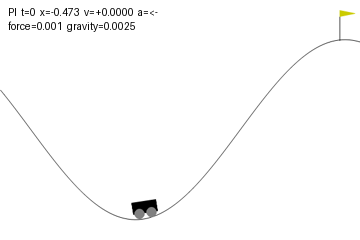

VI: ціль за 102 кроків


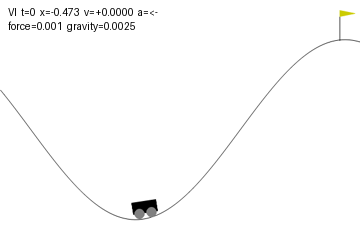

In [43]:
from IPython.display import Image, display
from PIL import Image as PILImage, ImageDraw

ARROWS = ["<-", "0", "->"]


def rollout_gif(policy, name, seed=0):
    renv = gym.make("MountainCar-v0", render_mode="rgb_array")
    (x, v), _ = renv.reset(seed=seed)
    frames, done, t = [], False, 0
    while True:
        a = int(policy[to_state(x, v)])
        img = PILImage.fromarray(renv.render()).resize((360, 240))
        draw = ImageDraw.Draw(img)
        draw.text((8, 6), f"{name}  t={t}  x={x:+.3f}  v={v:+.4f}  a={ARROWS[a]}", fill="black")
        draw.text((8, 20), f"force={car.force}  gravity={car.gravity}", fill="black")
        frames.append(img)
        if done:
            break
        (x, v), _, term, trunc, _ = renv.step(a)
        done, t = term or trunc, t + 1
    renv.close()
    path = OUT / f"rollout_{name}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:-1:2] + frames[-1:], duration=50, loop=0)
    print(f"{name}: {'ціль' if term else 'ліміт'} за {t} кроків")
    display(Image(filename=path))


rollout_gif(pi_pi, "PI")
rollout_gif(pi_vi, "VI")

## Висновки

Обидва методи сходяться до однієї функції цінності: різниця V не перевищує порядку θ·γ/(1-γ). Політики різняться лише в комірках, де дві дії мають однакове Q, тому в середовищі вони дають однакову кількість успіхів і майже однакову довжину епізоду. Policy Iteration робить мало зовнішніх ітерацій, але кожна містить повне оцінювання політики, тому сумарно проходів більше, ніж у Value Iteration, яка оновлює V одразу через max.